# Proyecto #2: Pipeline de Machine Learning
## Notebook 04: Entrenamiento, ajuste y selección de modelos
### Predict Future Sales (Kaggle)

**Objetivo:** entrenar **5 modelos distintos con 3 configuraciones de hiperparámetros cada uno (15 modelos)**, compararlos con el **RMSE** en un periodo de validación secuencial y agregar el ganador como paso final del pipeline de preprocesamiento del notebook 03.

**División secuencial (no aleatoria):** como indica el enunciado, se entrena con los primeros meses y se valida con los últimos: **meses 0 a 26 para entrenamiento y 27 a 33 para validación**. Las filas de modelado empiezan en el mes 12 (primer mes con lag de 12 meses), así que el entrenamiento efectivo son los meses 12 a 26; los meses 0 a 11 aportan la historia de los lags.

**Variables exógenas:** el modelo predice `item_cnt_month` usando la **tienda** (`shop_id` y su ciudad, codificadas por nivel de ventas) y el **producto** (su categoría, tipo y subtipo, su precio, su antigüedad, las banderas de producto o par nuevo y sus lags agregados) como variables exógenas, además de los lags de la propia serie.

**Salida:** `models/full_pipeline.pkl` con el preprocesamiento y el modelo ganador, reentrenado con los meses 12 a 33.

In [1]:
import gc
import time
from pathlib import Path

import joblib
import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.base import clone
from sklearn.ensemble import ExtraTreesRegressor, HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import Lasso
from sklearn.pipeline import Pipeline

from predict_future_sales import features as F
from predict_future_sales.dataset import load_raw

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.float_format", "{:,.4f}".format)
sns.set_theme(style="whitegrid")
COLOR, COLOR_2 = "#2f6fae", "#d9822b"
MODELS_DIR = Path("../models")
SEED = 42


def rmse(y_real, y_pred):
    """RMSE con las predicciones recortadas a [0, 20], igual que el objetivo y que la evaluación de Kaggle."""
    y_pred = np.clip(y_pred, *F.TARGET_CLIP)
    return float(np.sqrt(np.mean((np.asarray(y_real, dtype=np.float64) - y_pred) ** 2)))

## 1. Datos: la misma función de lags y el pipeline del notebook 03

La tabla se construye con la **misma función** `build_feature_matrix` de los notebooks 02, 03 y 05 (los lags se calculan fuera del pipeline, como se explicó en esos notebooks). Después se carga `models/preprocessing_pipeline.pkl`, que ya está ajustado con los meses 12 a 26, y se usa para transformar el entrenamiento y la validación **una sola vez**.

Esto equivale a entrenar 15 pipelines completos (preprocesamiento + modelo) con los meses 12 a 26, porque el preprocesamiento sería idéntico en los 15; transformar una sola vez ahorra tiempo y memoria.

In [2]:
raw = load_raw()
matriz = F.build_feature_matrix(raw)
X_train, y_train = F.split_xy(matriz, range(F.FIRST_MODEL_MONTH, F.LAST_TRAIN_MONTH + 1))
X_valid, y_valid = F.split_xy(matriz, range(F.LAST_TRAIN_MONTH + 1, F.TEST_MONTH))
del matriz
gc.collect()

preprocesamiento = joblib.load(MODELS_DIR / "preprocessing_pipeline.pkl")
inicio = time.time()
Xt_train = preprocesamiento.transform(X_train)
Xt_valid = preprocesamiento.transform(X_valid)
print(f"Transformación: {time.time() - inicio:,.1f} s")
print(f"Entrenamiento: {Xt_train.shape[0]:,} filas x {Xt_train.shape[1]} columnas (meses 12-26)")
print(f"Validación:    {Xt_valid.shape[0]:,} filas x {Xt_valid.shape[1]} columnas (meses 27-33)")
print(f"Memoria de las matrices transformadas: {(Xt_train.memory_usage().sum() + Xt_valid.memory_usage().sum()) / 1e6:,.0f} MB")

# Muestra fija del entrenamiento para medir el RMSE de entrenamiento sin predecir 4.8 millones de filas
idx_muestra = np.random.default_rng(SEED).choice(len(Xt_train), 500_000, replace=False)
Xt_muestra, y_muestra = Xt_train.iloc[idx_muestra], y_train.iloc[idx_muestra]

Transformación: 6.2 s
Entrenamiento: 4,810,730 filas x 24 columnas (meses 12-26)
Validación:    1,614,364 filas x 24 columnas (meses 27-33)
Memoria de las matrices transformadas: 617 MB


### Tienda y producto como variables exógenas

El enunciado pide que el modelo prediga `item_cnt_month` considerando la **tienda** y el **producto** como variables exógenas o banderas, es decir, como información externa a la propia serie de ventas que ayuda a explicarla. Además de los lags del par, el modelo recibe:

**Tienda:**
- `shop_id`, que entra **directamente** como variable, codificada con `OrdinalEncoder(encoding_method="ordered")`: cada tienda recibe un código según su venta media en el entrenamiento (la tienda 31, la más grande del EDA, recibe el código más alto). Así el modelo distingue el nivel de cada sucursal.
- `shop_city`, codificada de la misma forma, para compartir información entre tiendas de una misma ciudad.
- `shop_avg_cnt_lag_1` y `shop_cat_avg_cnt_lag_1`: el nivel de ventas reciente de la tienda y de cada categoría dentro de ella.

**Producto:**
- `item_category_id` (codificada por venta media), el subtipo `item_cat_subtype` (codificado igual) y el tipo `item_cat_type` (6 banderas one-hot): describen qué clase de producto es.
- `item_avg_cnt_lag_1`: las ventas del producto en todas las tiendas el mes anterior, junto con los lags 1, 2, 3, 6 y 12 del par tienda-producto.
- `item_price_last`: el último precio conocido del producto.
- `item_age` y las banderas `item_is_new` (producto sin ventas previas) y `shop_item_is_new` (producto que nunca se vendió en esa tienda).

**Por qué se elimina `item_id` como número crudo:** `item_id` es una etiqueta arbitraria, no una cantidad. Si entrara como número, el modelo supondría un orden y una distancia que no existen (el producto 5000 no se parece más al 5001 que al 20000), y un árbol podría dividir rangos de IDs sin sentido. Tampoco se puede codificar: con unos 22,000 productos, un one-hot sería inmanejable en memoria, y una codificación por venta media sería muy ruidosa para los miles de productos con pocas ventas. Además, los 363 productos nuevos de test no tienen ningún valor aprendido. Por eso la identidad del producto se representa con su **historial de ventas, su categoría, su precio y su antigüedad**, que sí existen (o se imputan) para cualquier producto, incluidos los nuevos.

## 2. Modelos de referencia (baselines)

Antes de entrenar, se calculan dos referencias que cualquier modelo útil debe superar:

- **Predecir 0** para todos los pares (la mayoría de los pares no vende).
- **Predecir el lag 1** (las ventas del mes anterior del mismo par), el pronóstico ingenuo de una serie de tiempo.

In [3]:
baselines = pd.DataFrame(
    {
        "RMSE validación": [
            rmse(y_valid, np.zeros(len(y_valid))),
            rmse(y_valid, X_valid["item_cnt_month_lag_1"].fillna(0).to_numpy()),
        ]
    },
    index=["Predecir 0", "Predecir el lag 1 (mes anterior)"],
)
baselines

,RMSE validación
Predecir 0,1.1159
Predecir el lag 1 (mes anterior),1.0373


**Interpretación de los baselines:**

- Predecir **0** para todos los pares da un RMSE de **1.1159**. Como el 86% de los pares no vende en un mes, este valor es bajo para un modelo que no aprende nada, y es el piso mínimo a superar.
- Predecir **las ventas del mes anterior** (lag 1) mejora a **1.0373**. Es el pronóstico ingenuo de series de tiempo y la referencia principal: un modelo que no le gane no aprovecha las variables exógenas ni los demás lags.

## 3. Entrenamiento de los 15 modelos

| Modelo | Tipo | Configuraciones (hiperparámetros que cambian) |
|---|---|---|
| **Extra Trees** | Bagging de árboles con cortes aleatorios | profundidad 12, 16 y 24 con hoja mínima 1, 20 y 50 |
| **Lasso** | Lineal con penalización L1 (selecciona variables) | `alpha` = 0.0001, 0.001, 0.01 |
| **Random Forest** | Bagging de árboles | profundidad 8, 12 y 16, fracción de variables por división y tamaño mínimo de hoja |
| **HistGradientBoosting** | Boosting de árboles (sklearn) | número de iteraciones, tasa de aprendizaje, hojas por árbol y regularización L2 |
| **LightGBM** | Boosting de árboles (crecimiento por hojas) | número de árboles, tasa de aprendizaje, hojas por árbol, submuestreo de filas y columnas |

**Criterios de diseño:**

- Lasso sirve como referencia lineal e interpretable; para él se escalaron las variables en el notebook 03.
- En una primera versión el modelo lineal de referencia era también **Ridge** (`alpha` = 0.1, 10 y 1000), pero las tres configuraciones dieron el mismo RMSE de validación (0.9027): con 4.8 millones de filas y 24 variables la penalización L2 es despreciable, así que no era un ajuste real de hiperparámetros. Se reemplazó por **Extra Trees**, cuyas configuraciones sí cambian el resultado.
- Random Forest y Extra Trees se entrenan con `max_samples=0.1` (cada árbol ve unas 480,000 filas al azar) para que quepan en memoria y terminen en un tiempo razonable con 4.8 millones de filas. Extra Trees elige los puntos de corte al azar en lugar de buscar el óptimo, lo que lo hace más rápido y suele reducir la varianza.
- En los modelos de boosting se desactiva la parada temprana (`early_stopping=False` en HistGradientBoosting), porque usaría una partición **aleatoria** del entrenamiento, lo que rompe el orden temporal. El número de iteraciones es uno de los hiperparámetros que se comparan.
- Todos los modelos usan la semilla 42 cuando tienen componentes aleatorios.
- Cada modelo se evalúa con el RMSE de validación (meses 27 a 33) con las predicciones recortadas a [0, 20].
- **Resultados guardados:** el RMSE de cada modelo se guarda en `reports/model_results.csv`. Al volver a ejecutar el notebook, los modelos que ya están en ese archivo no se reentrenan (se lee su resultado) y solo se entrenan los nuevos; para reentrenar todo basta con borrar el archivo. Todos los modelos usan semilla fija, así que el resultado sería el mismo.

In [4]:
modelos = {
    # --- Extra Trees (reemplaza a Ridge) ---
    "ExtraTrees | depth=12, leaf=1": ExtraTreesRegressor(
        n_estimators=60, max_depth=12, min_samples_leaf=1, max_features=0.5,
        bootstrap=True, max_samples=0.1, n_jobs=-1, random_state=SEED),
    "ExtraTrees | depth=16, leaf=20": ExtraTreesRegressor(
        n_estimators=60, max_depth=16, min_samples_leaf=20, max_features=0.5,
        bootstrap=True, max_samples=0.1, n_jobs=-1, random_state=SEED),
    "ExtraTrees | depth=24, leaf=50": ExtraTreesRegressor(
        n_estimators=60, max_depth=24, min_samples_leaf=50, max_features=0.7,
        bootstrap=True, max_samples=0.1, n_jobs=-1, random_state=SEED),
    # --- Lasso ---
    "Lasso | alpha=0.0001": Lasso(alpha=0.0001, random_state=SEED),
    "Lasso | alpha=0.001": Lasso(alpha=0.001, random_state=SEED),
    "Lasso | alpha=0.01": Lasso(alpha=0.01, random_state=SEED),
    # --- Random Forest ---
    "RandomForest | depth=8": RandomForestRegressor(
        n_estimators=40, max_depth=8, max_features=0.5, max_samples=0.1, n_jobs=-1, random_state=SEED),
    "RandomForest | depth=12": RandomForestRegressor(
        n_estimators=40, max_depth=12, max_features=0.5, max_samples=0.1, n_jobs=-1, random_state=SEED),
    "RandomForest | depth=16, leaf=20": RandomForestRegressor(
        n_estimators=60, max_depth=16, max_features=0.33, min_samples_leaf=20, max_samples=0.1, n_jobs=-1, random_state=SEED),
    # --- HistGradientBoosting ---
    "HistGB | iter=200, lr=0.1, leaves=31": HistGradientBoostingRegressor(
        max_iter=200, learning_rate=0.1, max_leaf_nodes=31, early_stopping=False, random_state=SEED),
    "HistGB | iter=300, lr=0.05, leaves=63": HistGradientBoostingRegressor(
        max_iter=300, learning_rate=0.05, max_leaf_nodes=63, early_stopping=False, random_state=SEED),
    "HistGB | iter=300, lr=0.1, leaves=127, l2=1": HistGradientBoostingRegressor(
        max_iter=300, learning_rate=0.1, max_leaf_nodes=127, l2_regularization=1.0, early_stopping=False, random_state=SEED),
    # --- LightGBM ---
    "LightGBM | n=300, lr=0.05, leaves=31": lgb.LGBMRegressor(
        n_estimators=300, learning_rate=0.05, num_leaves=31, random_state=SEED, n_jobs=-1, verbose=-1),
    "LightGBM | n=500, lr=0.05, leaves=63, sub=0.8": lgb.LGBMRegressor(
        n_estimators=500, learning_rate=0.05, num_leaves=63, subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
        random_state=SEED, n_jobs=-1, verbose=-1),
    "LightGBM | n=800, lr=0.03, leaves=127, sub=0.7": lgb.LGBMRegressor(
        n_estimators=800, learning_rate=0.03, num_leaves=127, min_child_samples=100, subsample=0.7, subsample_freq=1,
        colsample_bytree=0.7, random_state=SEED, n_jobs=-1, verbose=-1),
}
print("Modelos a entrenar:", len(modelos), "| familias:", len({n.split(" | ")[0] for n in modelos}))

Modelos a entrenar: 15 | familias: 5


In [5]:
RESULTADOS_CSV = Path("../reports/model_results.csv")
COLUMNAS = ["modelo", "configuración", "RMSE entrenamiento", "RMSE validación", "segundos"]
previos = pd.read_csv(RESULTADOS_CSV, index_col="nombre") if RESULTADOS_CSV.exists() else pd.DataFrame(columns=COLUMNAS)

resultados = []
for nombre, modelo in modelos.items():
    if nombre in previos.index:
        fila = previos.loc[nombre, COLUMNAS].to_dict()
        fila["origen"] = "resultado guardado"
    else:
        inicio = time.time()
        modelo.fit(Xt_train, y_train)
        fila = {
            "modelo": nombre.split(" | ")[0],
            "configuración": nombre.split(" | ")[1],
            "RMSE entrenamiento": rmse(y_muestra, modelo.predict(Xt_muestra)),
            "RMSE validación": rmse(y_valid, modelo.predict(Xt_valid)),
            "segundos": time.time() - inicio,
            "origen": "entrenado en esta ejecución",
        }
        gc.collect()
    resultados.append(fila)
    print(f"{nombre:<50} RMSE valid = {fila['RMSE validación']:.4f} | {fila['segundos']:>5,.0f} s | {fila['origen']}", flush=True)

resultados = pd.DataFrame(resultados, index=pd.Index(list(modelos), name="nombre")).sort_values("RMSE validación")
resultados[COLUMNAS].to_csv(RESULTADOS_CSV)
resultados["brecha (valid - train)"] = resultados["RMSE validación"] - resultados["RMSE entrenamiento"]
resultados

ExtraTrees | depth=12, leaf=1                      RMSE valid = 0.8103 |    31 s | entrenado en esta ejecución


ExtraTrees | depth=16, leaf=20                     RMSE valid = 0.8105 |    38 s | entrenado en esta ejecución


ExtraTrees | depth=24, leaf=50                     RMSE valid = 0.8136 |    55 s | entrenado en esta ejecución


Lasso | alpha=0.0001                               RMSE valid = 0.9027 |    24 s | resultado guardado


Lasso | alpha=0.001                                RMSE valid = 0.9029 |     9 s | resultado guardado


Lasso | alpha=0.01                                 RMSE valid = 0.9054 |    14 s | resultado guardado


... (6 outputs left out)

LightGBM | n=300, lr=0.05, leaves=31               RMSE valid = 0.8158 |    26 s | resultado guardado


LightGBM | n=500, lr=0.05, leaves=63, sub=0.8      RMSE valid = 0.8160 |    51 s | resultado guardado


LightGBM | n=800, lr=0.03, leaves=127, sub=0.7     RMSE valid = 0.8129 |   111 s | resultado guardado


,modelo,configuración,RMSE entrenamiento,RMSE validación,segundos,origen,brecha (valid - train)
nombre,,,,,,,
"RandomForest | depth=16, leaf=20",RandomForest,"depth=16, leaf=20",0.8295,0.8073,38.1498,resultado guardado,-0.0222
"ExtraTrees | depth=12, leaf=1",ExtraTrees,"depth=12, leaf=1",0.8328,0.8103,30.7083,entrenado en esta ejecución,-0.0225
"ExtraTrees | depth=16, leaf=20",ExtraTrees,"depth=16, leaf=20",0.8472,0.8105,38.1262,entrenado en esta ejecución,-0.0367
"LightGBM | n=800, lr=0.03, leaves=127, sub=0.7",LightGBM,"n=800, lr=0.03, leaves=127, sub=0.7",0.7472,0.8129,111.0290,resultado guardado,0.0657
"ExtraTrees | depth=24, leaf=50",ExtraTrees,"depth=24, leaf=50",0.8569,0.8136,54.6335,entrenado en esta ejecución,-0.0433
RandomForest | depth=12,RandomForest,depth=12,0.8103,0.8151,29.5545,resultado guardado,0.0048
"LightGBM | n=300, lr=0.05, leaves=31",LightGBM,"n=300, lr=0.05, leaves=31",0.7955,0.8158,26.4575,resultado guardado,0.0203
"LightGBM | n=500, lr=0.05, leaves=63, sub=0.8",LightGBM,"n=500, lr=0.05, leaves=63, sub=0.8",0.7574,0.8160,50.8569,resultado guardado,0.0586
"HistGB | iter=300, lr=0.05, leaves=63",HistGB,"iter=300, lr=0.05, leaves=63",0.7766,0.8164,73.7295,resultado guardado,0.0398


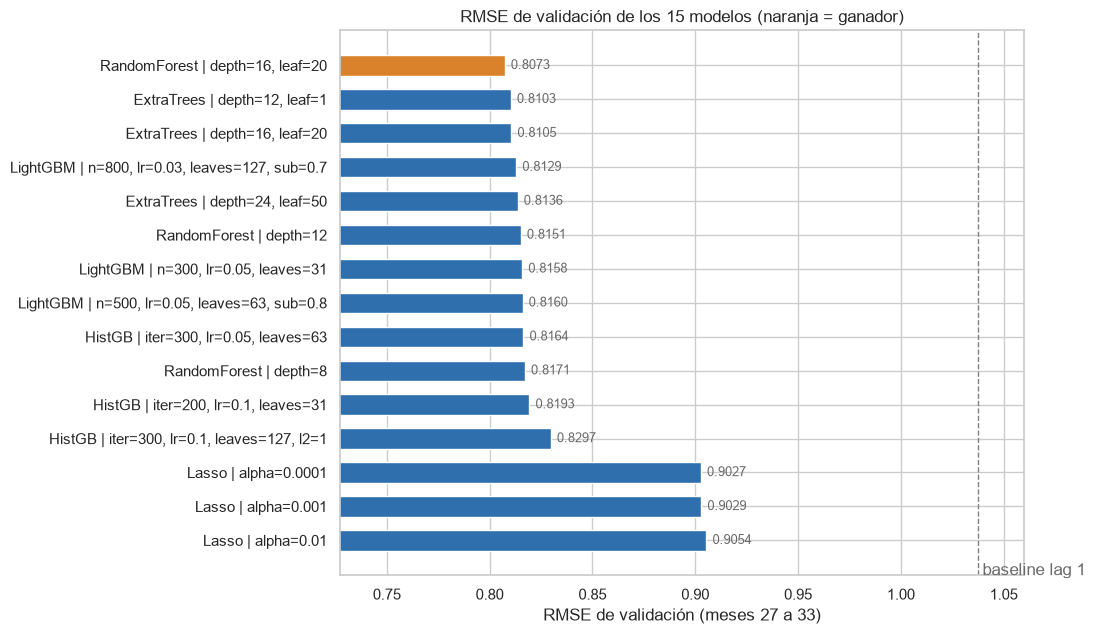

Mejor configuración de cada modelo:


,modelo,configuración,RMSE entrenamiento,RMSE validación,segundos
nombre,,,,,
"RandomForest | depth=16, leaf=20",RandomForest,"depth=16, leaf=20",0.8295,0.8073,38.1498
"ExtraTrees | depth=12, leaf=1",ExtraTrees,"depth=12, leaf=1",0.8328,0.8103,30.7083
"LightGBM | n=800, lr=0.03, leaves=127, sub=0.7",LightGBM,"n=800, lr=0.03, leaves=127, sub=0.7",0.7472,0.8129,111.0290
"HistGB | iter=300, lr=0.05, leaves=63",HistGB,"iter=300, lr=0.05, leaves=63",0.7766,0.8164,73.7295
Lasso | alpha=0.0001,Lasso,alpha=0.0001,0.9760,0.9027,24.0774


In [6]:
fig, ax = plt.subplots(figsize=(11, 6.5))
orden = resultados.sort_values("RMSE validación", ascending=False)
colores = [COLOR_2 if n == resultados.index[0] else COLOR for n in orden.index]
ax.barh(orden.index, orden["RMSE validación"], color=colores, height=0.6)
ax.axvline(baselines.loc["Predecir el lag 1 (mes anterior)", "RMSE validación"], color="gray", linestyle="--", linewidth=1)
ax.text(baselines.loc["Predecir el lag 1 (mes anterior)", "RMSE validación"], -0.9, " baseline lag 1", color="dimgray", va="center")
for y_pos, valor in enumerate(orden["RMSE validación"]):
    ax.text(valor + 0.003, y_pos, f"{valor:.4f}", va="center", fontsize=9, color="dimgray")
ax.set_xlim(orden["RMSE validación"].min() - 0.08, max(orden["RMSE validación"].max(), 1.0) + 0.06)
ax.set_xlabel("RMSE de validación (meses 27 a 33)")
ax.set_title("RMSE de validación de los 15 modelos (naranja = ganador)")
plt.tight_layout()
plt.show()

print("Mejor configuración de cada modelo:")
mejores = resultados.groupby("modelo", sort=False).head(1)
display(mejores[["modelo", "configuración", "RMSE entrenamiento", "RMSE validación", "segundos"]])

**Interpretación del torneo de 15 modelos:**

- **Todos los modelos superan a los dos baselines.** Incluso el peor (Lasso con `alpha=0.01`, 0.9054) mejora 13% al lag 1, y el mejor (Random Forest, 0.8073) lo mejora **22%**.
- **Los modelos de árboles dominan:** las 12 configuraciones de Random Forest, Extra Trees, LightGBM e HistGradientBoosting quedan entre 0.807 y 0.830, mientras que Lasso se queda en 0.903. La relación entre los lags, la tienda, la categoría y la venta no es lineal (por ejemplo, un producto nuevo vende mucho en su primer mes y casi nada en tiendas donde nunca se vendió), y los árboles capturan esas interacciones.
- **Los hiperparámetros sí cambian el resultado:** en Random Forest, pasar de profundidad 8 a 16 con hoja mínima 20 mejora de 0.8171 a 0.8073; en Extra Trees, la profundidad 24 con hoja mínima 50 empeora a 0.8136; en HistGradientBoosting, 127 hojas con tasa 0.1 sobreajusta (0.8297, con la mayor brecha entre entrenamiento y validación, 0.105). En Lasso, una penalización mayor (`alpha=0.01`) empeora el RMSE porque elimina variables útiles.
- **Extra Trees** (que reemplazó a Ridge, cuyas tres configuraciones daban el mismo 0.9027) queda en segundo lugar con 0.8103, muy cerca del ganador, pero no lo supera, así que el ganador sigue siendo Random Forest.
- La columna **brecha (valid − train)** mide el sobreajuste. Los modelos de boosting tienen brechas positivas de 0.02 a 0.10 (ajustan mejor el entrenamiento de lo que generalizan), mientras que Random Forest y Extra Trees con `max_samples=0.1` y hoja mínima tienen brechas negativas o casi nulas: su error de validación es incluso menor que el de entrenamiento, señal de que no memorizan el entrenamiento.

## 4. Análisis del modelo ganador

In [7]:
nombre_ganador = resultados.index[0]
ganador = modelos[nombre_ganador]
print("Modelo ganador:", nombre_ganador)
if not hasattr(ganador, "n_features_in_"):
    # El resultado del ganador venía de reports/model_results.csv: se vuelve a ajustar (misma semilla) para analizarlo
    inicio = time.time()
    ganador.fit(Xt_train, y_train)
    print(f"Ganador reajustado con los meses 12-26 en {time.time() - inicio:,.0f} s")
print("RMSE de validación guardado:", round(resultados.loc[nombre_ganador, "RMSE validación"], 4),
      "| recalculado:", round(rmse(y_valid, ganador.predict(Xt_valid)), 4))

# Error por mes de validación, frente al baseline del lag 1
pred_valid = np.clip(ganador.predict(Xt_valid), *F.TARGET_CLIP)
por_mes = pd.DataFrame({
    "mes": X_valid["date_block_num"].to_numpy(),
    "real": y_valid.to_numpy(),
    "pred": pred_valid,
    "lag1": X_valid["item_cnt_month_lag_1"].fillna(0).clip(*F.TARGET_CLIP).to_numpy(),
})
resumen_mes = por_mes.groupby("mes").apply(
    lambda g: pd.Series({
        "RMSE ganador": np.sqrt(((g["real"] - g["pred"]) ** 2).mean()),
        "RMSE lag 1": np.sqrt(((g["real"] - g["lag1"]) ** 2).mean()),
        "venta real total": g["real"].sum(),
        "venta predicha total": g["pred"].sum(),
    }), include_groups=False,
)
display(resumen_mes)

Modelo ganador: RandomForest | depth=16, leaf=20


Ganador reajustado con los meses 12-26 en 35 s


RMSE de validación guardado: 0.8073 | recalculado: 0.8073


,RMSE ganador,RMSE lag 1,venta real total,venta predicha total
mes,,,,
27,0.8588,1.1181,"62,550.0000","75,545.4947"
28,0.7933,1.0893,"60,331.0000","58,009.5552"
29,0.7629,0.9719,"59,274.0000","57,764.0351"
30,0.7013,0.8903,"59,335.0000","56,369.3388"
31,0.7611,0.9441,"61,784.0000","54,260.2048"
32,0.8637,1.0640,"57,672.0000","64,813.5719"
33,0.8828,1.1358,"61,583.0000","64,514.0521"


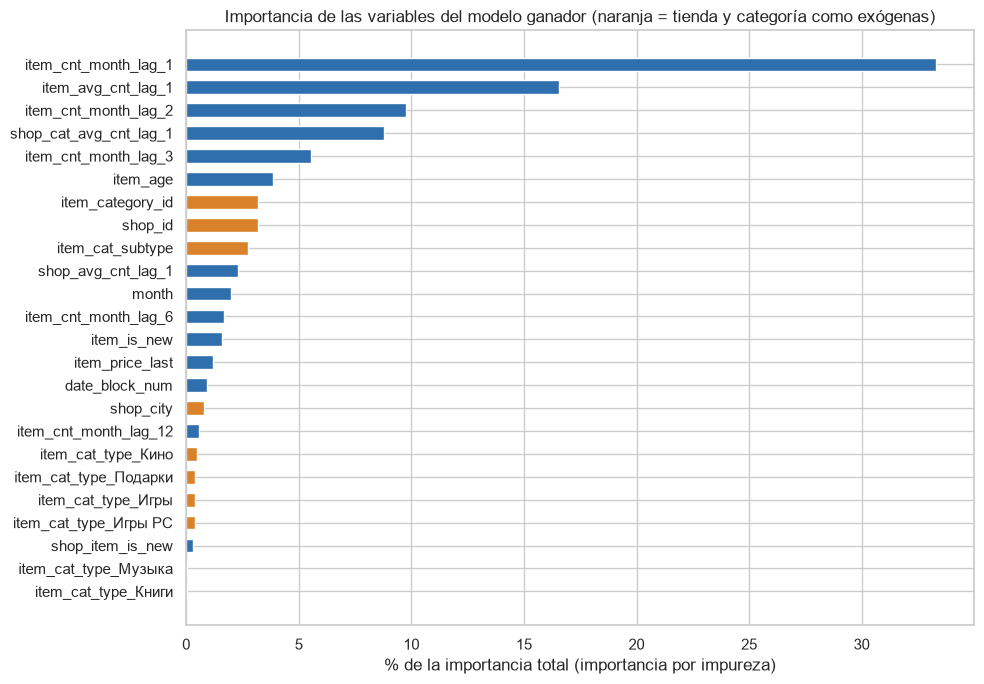

Importancia conjunta de las variables exógenas de tienda y categoría: 11.6%


In [8]:
# Importancia de las variables (si el ganador es un modelo de árboles)
if hasattr(ganador, "booster_"):
    importancia = pd.Series(ganador.booster_.feature_importance(importance_type="gain"), index=Xt_train.columns)
    tipo = "ganancia total (gain) de LightGBM"
elif hasattr(ganador, "feature_importances_"):
    importancia = pd.Series(ganador.feature_importances_, index=Xt_train.columns)
    tipo = "importancia por impureza"
else:
    importancia = pd.Series(np.abs(ganador.coef_), index=Xt_train.columns)
    tipo = "|coeficiente| (variables escaladas)"
importancia = (importancia / importancia.sum() * 100).sort_values()

fig, ax = plt.subplots(figsize=(10, 7))
exogenas = {"shop_id", "shop_city", "item_category_id", "item_cat_subtype"} | {c for c in importancia.index if c.startswith("item_cat_type_")}
ax.barh(importancia.index, importancia, color=[COLOR_2 if c in exogenas else COLOR for c in importancia.index], height=0.6)
ax.set_xlabel(f"% de la importancia total ({tipo})")
ax.set_title("Importancia de las variables del modelo ganador (naranja = tienda y categoría como exógenas)")
plt.tight_layout()
plt.show()
print(f"Importancia conjunta de las variables exógenas de tienda y categoría: {importancia[list(exogenas & set(importancia.index))].sum():.1f}%")

**Por qué ganó Random Forest frente a LightGBM:**

- La diferencia de RMSE es **mínima**: 0.8073 contra 0.8129 del mejor LightGBM (0.0056, menos del 1%). Con un margen así, el criterio que define la elección, además del RMSE, es la **estabilidad**.
- **Random Forest sobreajusta menos.** Su RMSE de entrenamiento (0.8295) es prácticamente igual al de validación (0.8073), mientras que el mejor LightGBM baja a 0.7472 en el entrenamiento y sube a 0.8129 en validación (brecha de 0.066). LightGBM aprende patrones del entrenamiento que no se repiten en los meses siguientes; Random Forest, al promediar 60 árboles entrenados con muestras distintas del 10% de las filas y hojas de al menos 20 filas, produce predicciones más suaves y robustas al cambio de distribución entre los meses 12-26 y 27-33 (ventas cada vez menores, notebook 03).
- Esto importa porque el pipeline final predice un mes que nadie ha visto (noviembre de 2015), así que conviene el modelo que generaliza de forma más estable, no el que mejor memoriza.
- Al reajustar el ganador en esta ejecución (su resultado venía de `reports/model_results.csv`) se obtiene exactamente el mismo RMSE de validación, 0.8073, lo que confirma que el resultado es reproducible con la semilla fija.

**Error por mes de validación:** el ganador supera al lag 1 en los 7 meses (por ejemplo, 0.70 contra 0.89 en el mes 30). El total predicho se acerca al real en los meses 28 a 30; en el mes 27 (abril de 2015) sobreestima un 21% (75.5 mil contra 62.6 mil unidades), porque viene de marzo, un mes alto, y los lags no anticipan la caída de abril (−27% en 2013, según el EDA). En los meses 32 y 33 también sobreestima (unos 3 a 7 mil unidades), coherente con la tendencia decreciente: el modelo aprendió niveles de meses con más ventas.

**Importancia de las variables:** las más importantes son el **lag 1 del par (33%)** y la **venta media del producto el mes anterior (`item_avg_cnt_lag_1`, 17%)**, seguidas del lag 2, la venta de la categoría en la tienda (`shop_cat_avg_cnt_lag_1`) y el lag 3. Es lo que anticipaban la ACF/PACF del EDA y el notebook 02: domina la dependencia de corto plazo. El lag 12 tiene poca importancia (menos del 1%), igual que su aporte lineal en el notebook 02. Las variables exógenas de tienda y categoría (en naranja) suman el **11.6%**: `item_category_id`, `shop_id` y `item_cat_subtype` tienen cada una cerca del 3%. No son las principales, pero el modelo sí las usa para ajustar el nivel de cada tienda y tipo de producto, sobre todo en los pares sin historial propio.

## 5. Pipeline completo: reentrenamiento con los meses 12 a 33 y guardado

El pipeline final se forma con **los mismos pasos de preprocesamiento del notebook 03** (`clone` crea una copia sin ajustar, con los mismos hiperparámetros) más el **modelo ganador como paso final**. Se reentrena con los meses **12 a 33** (entrenamiento + validación) para que:

- el modelo aprenda de los meses más recientes, que son los más parecidos a noviembre de 2015;
- el preprocesamiento conozca las tiendas y categorías que aparecieron después del mes 26 (por ejemplo, la tienda 36, que solo vendió en octubre de 2015).

Los hiperparámetros son los que ganaron en la validación; no se vuelven a ajustar.

In [9]:
X_completo = pd.concat([X_train, X_valid])
y_completo = pd.concat([y_train, y_valid])
del Xt_train, Xt_valid, Xt_muestra
gc.collect()

pipeline_completo = Pipeline(clone(preprocesamiento).steps + [("modelo", clone(ganador))])
inicio = time.time()
pipeline_completo.fit(X_completo, y_completo)
print(f"Pipeline completo reentrenado con {len(X_completo):,} filas (meses 12-33) en {time.time() - inicio:,.0f} s")
print("Pasos:", [nombre for nombre, _ in pipeline_completo.steps])
print("¿La tienda 36 ya tiene código propio?:", 36 in pipeline_completo.named_steps["codificar_ordinal"].encoder_dict_["shop_id"])
print(f"RMSE en los meses 12-33 (dentro de la muestra): {rmse(y_completo, pipeline_completo.predict(X_completo)):.4f}")

Pipeline completo reentrenado con 6,425,094 filas (meses 12-33) en 60 s
Pasos: ['unificar_tiendas', 'imputar_lags', 'imputar_precio', 'imputar_categoricas', 'codificar_ordinal', 'codificar_onehot', 'eliminar_item_id', 'outliers_precio', 'log_precio', 'log_conteos', 'escalar', 'float32', 'modelo']
¿La tienda 36 ya tiene código propio?: True


RMSE en los meses 12-33 (dentro de la muestra): 0.8215


In [10]:
ruta = MODELS_DIR / "full_pipeline.pkl"
joblib.dump(pipeline_completo, ruta)
print(f"Pipeline completo guardado en {ruta} ({ruta.stat().st_size / 1e6:,.1f} MB)")

cargado = joblib.load(ruta)
muestra = X_valid.sample(10_000, random_state=SEED)
print("¿El pipeline cargado predice lo mismo?:", np.allclose(cargado.predict(muestra), pipeline_completo.predict(muestra)))

Pipeline completo guardado en ..\models\full_pipeline.pkl (30.0 MB)


¿El pipeline cargado predice lo mismo?: True


**Conclusión:**

- Se entrenaron **15 modelos** (5 familias x 3 configuraciones: Lasso, Extra Trees, Random Forest, HistGradientBoosting y LightGBM), comparados con el RMSE en los meses 27 a 33 con división secuencial.
- **Ganador: Random Forest** (60 árboles, profundidad 16, hoja mínima 20, 33% de las variables por división, 10% de las filas por árbol), con **RMSE de validación de 0.8073**, 22% mejor que el baseline del lag 1 (1.0373) y con el menor sobreajuste entre los mejores modelos de árboles.
- El pipeline completo (los 12 pasos de preprocesamiento del notebook 03 + el Random Forest como paso 13) se reentrenó con los meses 12 a 33 y se guardó en **`models/full_pipeline.pkl`** (30 MB). Al cargarlo desde disco predice lo mismo y ya reconoce la tienda 36. El RMSE dentro de la muestra (0.8215) es similar al de validación, otra señal de que el modelo no memoriza.
- Los resultados de los 15 modelos quedan en `reports/model_results.csv`. El notebook 05 usa `full_pipeline.pkl` para predecir noviembre de 2015.